# ⚽🏟️ Projeto: O "Fator Casa" e a Influência do Público no Desempenho no Brasileirão

## 1. Contexto e Objetivo
Neste projeto, vamos explorar duas grandes crenças do futebol brasileiro utilizando Ciência de Dados:
1. **O "Fator Casa":** Jogar em seus domínios realmente garante uma vantagem competitiva significativa?
2. **O Peso da Torcida:** Equipes que levam mais público aos estádios tendem a terminar o campeonato em melhores posições na tabela?

Para responder a essas perguntas, analisaremos dados históricos de partidas, classificação final e média de público do Campeonato Brasileiro.

**Fontes de Dados (Kaggle):**
* [Histórico do Campeonato Brasileiro (2003-2024)](https://www.kaggle.com/datasets/lucasyukioimafuko/brasileirao-serie-a-2006-2022)
* [Histórico de Partidas e média de público.](https://www.kaggle.com/datasets/rczekster/matches-brazilian-football-from-2003-to-2019)

In [ ]:
from google.colab import auth

try:
    auth.authenticate_user()
    print("Usuário autenticado com sucesso no Google Cloud!")
except Exception as e:
    print(f"[Erro de Autenticação]: {e}")

Usuário autenticado com sucesso no Google Cloud!


In [ ]:
from google.cloud import bigquery
import sys

client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_brazilian_league`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_brasileirao = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


## 2. Importação de Bibliotecas e Carregamento dos Dados
Nesta etapa, vamos importar as ferramentas necessárias (como `pandas`, `matplotlib` e `seaborn`) e carregar os nossos conjuntos de dados.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## ⚽ Iniciando a criação dos dataframes

In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_brazilian_league`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_brasileirao = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

df_brasileirao.head()

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


,season,place,team,points,played,won,draw,loss,goals,goals_taken,goals_diff
0,2022,1,Palmeiras,81,38,23,12,3,66,27,39
1,2006,1,São Paulo,78,38,22,12,4,66,32,34
2,2018,1,Palmeiras,80,38,23,11,4,64,26,38
3,2019,1,Flamengo,90,38,28,6,4,86,37,49
4,2022,2,Internacional,73,38,20,13,5,58,31,27


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_matches`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_partidas = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

df_partidas.head()

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


,date,hour,home_team,score,away_team
0,07/10/2022,00:00,América Mineiro,1x2,São Paulo
1,22/07/2022,00:00,América Mineiro,0x1,Palmeiras
2,16/10/2022,00:30,América Mineiro,1x2,Fortaleza
3,04/09/2022,00:30,América Mineiro,2x0,Coritiba
4,22/05/2022,01:00,América Mineiro,1x1,Botafogo


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_public_matches`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_media_publico = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

df_media_publico

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


,year,team,avg_attendance
0,2003,Paraná,4419
1,2003,Bahia,12131
2,2003,Santos,7628
3,2003,Fluminense,5863
4,2003,Cruzeiro,23443
...,...,...,...
425,2025,Grêmio,25526
426,2025,Cruzeiro,40158
427,2025,Ceará,34702
428,2025,Fortaleza,26391


In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_teams`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_times = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

df_times.head()

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


,team,acronym,full_name,founded,stadium,city,state,region
0,Brasiliense,BRA,Brasiliense Futebol Clube,2000,Boca do Jacare,Taguatinga,Distrito Federal,Central
1,Atlético Goianiense,ACG,Atletico Clube Goianiense,1937,Estadio Antonio Accioly,Goiania,Goias,Central
2,Goiás,GOI,Goias Esporte Clube,1943,Estadio Serra Dourada,Goiania,Goias,Central
3,Cuiabá,CUI,Cuiaba Esporte Clube,2001,Arena Pantanal,Cuiaba,Mato Grosso,Central
4,Paysandu,PAY,Paysandu Sport Club,1914,Mangueirao,Belem,Para,North


## 3. Preparação e Limpeza dos Dados
Antes de qualquer análise, precisamos garantir que os dados estão consistentes. Vamos verificar valores nulos, padronizar nomes de times (se necessário) e preparar os dados para o cruzamento.

In [ ]:
df_partidas = pd.DataFrame(df_partidas)

df_partidas [['home_team_score', 'away_team_score']] = df_partidas['score'].str.split('x', expand=True)
df_partidas.head()

,date,hour,home_team,score,away_team,home_team_score,away_team_score
0,07/10/2022,00:00,América Mineiro,1x2,São Paulo,1,2
1,22/07/2022,00:00,América Mineiro,0x1,Palmeiras,0,1
2,16/10/2022,00:30,América Mineiro,1x2,Fortaleza,1,2
3,04/09/2022,00:30,América Mineiro,2x0,Coritiba,2,0
4,22/05/2022,01:00,América Mineiro,1x1,Botafogo,1,1


In [ ]:
colunas_placar = ['home_team_score', 'away_team_score']
df_partidas[colunas_placar] = df_partidas[colunas_placar].apply(pd.to_numeric, errors='coerce').astype(int)

In [ ]:
df_partidas['date'] = pd.to_datetime(df_partidas['date'], format='%d/%m/%Y')
df_partidas.head()

,date,hour,home_team,score,away_team,home_team_score,away_team_score
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1


In [ ]:
soma_gols = df_partidas['home_team_score'] + df_partidas['away_team_score']
df_partidas['total_gols'] = soma_gols
df_partidas.head()

,date,hour,home_team,score,away_team,home_team_score,away_team_score,total_gols
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2,3
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2,3
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0,2
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1,2


In [ ]:
colunas_media = ['year', 'avg_attendance']
df_media_publico[colunas_media] = df_media_publico[colunas_media].apply(pd.to_numeric, errors='coerce').astype(int)
df_media_publico.head()

,year,team,avg_attendance
0,2003,Paraná,4419
1,2003,Bahia,12131
2,2003,Santos,7628
3,2003,Fluminense,5863
4,2003,Cruzeiro,23443


## 4. Análise Parte 1: A Vantagem do Mandante
Vamos calcular a taxa de vitórias dos times quando jogam em casa versus quando jogam fora.

**Perguntas a responder:**
* Qual a porcentagem de vitórias dos mandantes em todo o histórico?
* Essa taxa tem mudado ao longo dos anos?

1° Pergunta: Qual a porcentagem de vitórias dos mandantes em todo o histórico?

In [ ]:
df_partidas_mandante = df_partidas.copy()
df_partidas_mandante.head()

,date,hour,home_team,score,away_team,home_team_score,away_team_score,total_gols
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2,3
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2,3
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0,2
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1,2


In [ ]:
df_partidas_mandante['resultado_mandante'] = np.where (
    df_partidas_mandante['home_team_score'] > df_partidas_mandante['away_team_score'], 'Vitoria',
    np.where(df_partidas_mandante['home_team_score'] == df_partidas_mandante['away_team_score'], 'Empate', 'Derrota')
)

df_partidas_mandante.head()

,date,hour,home_team,score,away_team,home_team_score,away_team_score,total_gols,resultado_mandante
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2,3,Derrota
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1,1,Derrota
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2,3,Derrota
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0,2,Vitoria
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1,2,Empate


In [ ]:
resultados_percentuais = df_partidas_mandante['resultado_mandante'].value_counts(normalize=True).round(3) * 100
print(resultados_percentuais)

resultado_mandante
Vitoria    49.6
Empate     26.4
Derrota    23.9
Name: proportion, dtype: float64


2° Pergunta: Essa taxa tem mudado ao longo dos anos?

In [ ]:
df_partidas_mandante['date'] = pd.to_datetime(df_partidas_mandante['date'], format='%d/%m/%Y').dt.year
df_partidas_mandante

,date,hour,home_team,score,away_team,home_team_score,away_team_score,total_gols,resultado_mandante
0,2022,00:00,América Mineiro,1x2,São Paulo,1,2,3,Derrota
1,2022,00:00,América Mineiro,0x1,Palmeiras,0,1,1,Derrota
2,2022,00:30,América Mineiro,1x2,Fortaleza,1,2,3,Derrota
3,2022,00:30,América Mineiro,2x0,Coritiba,2,0,2,Vitoria
4,2022,01:00,América Mineiro,1x1,Botafogo,1,1,2,Empate
...,...,...,...,...,...,...,...,...,...
9161,2025,22:30,Vitória,1x0,Atlético Mineiro,1,0,1,Vitoria
9162,2025,22:30,Vitória,0x1,Santos,0,1,1,Derrota
9163,2025,23:00,Vitória,0x0,Cruzeiro,0,0,0,Empate
9164,2025,23:00,Vitória,1x0,Ceará,1,0,1,Vitoria


In [ ]:
normalize='index'
evolucao_fator_casa = pd.crosstab(df_partidas_mandante['date'], df_partidas_mandante['resultado_mandante'], normalize=normalize) *100
print(evolucao_fator_casa.round(2))

resultado_mandante  Derrota  Empate  Vitoria
date                                        
2003                  20.47   25.72    53.80
2004                  22.46   25.36    52.17
2005                  27.06   22.08    50.87
2006                  24.21   25.53    50.26
2007                  25.79   23.68    50.53
2008                  20.00   25.26    54.74
2009                  21.84   26.84    51.32
2010                  21.84   31.05    47.11
2011                  23.95   27.63    48.42
2012                  24.21   27.63    48.16
2013                  23.16   28.42    48.42
2014                  23.95   24.21    51.84
2015                  23.42   23.95    52.63
2016                  21.84   25.00    53.16
2017                  28.95   27.11    43.95
2018                  17.89   28.95    53.16
2019                  25.79   25.79    48.42
2020                  26.58   28.42    45.00
2021                  24.47   29.74    45.79
2022                  27.37   28.42    44.21
2023      

## 5. Análise Parte 2: Cruzamento de Público e Desempenho
Agora, vamos unir (`merge`) os dados de classificação final com as médias de público de cada temporada.

**Perguntas a responder:**
* Existe uma correlação forte entre a média de público e a pontuação final do time?
* Times campeões ou no G4 sempre têm as maiores médias de público?

In [ ]:
df_desempenho_publico = pd.merge(
    df_brasileirao,
    df_media_publico,
    left_on= ['season', 'team'],
    right_on=['year', 'team'],
    how='inner'
)

df_desempenho_publico.head()

,season,place,team,points,played,won,draw,loss,goals,goals_taken,goals_diff,year,avg_attendance
0,2022,1,Palmeiras,81,38,23,12,3,66,27,39,2022,35943
1,2006,1,São Paulo,78,38,22,12,4,66,32,34,2006,36280
2,2018,1,Palmeiras,80,38,23,11,4,64,26,38,2018,32356
3,2019,1,Flamengo,90,38,28,6,4,86,37,49,2019,52537
4,2022,2,Internacional,73,38,20,13,5,58,31,27,2022,22858


1° Pergunta: Existe uma correlação forte entre a média de público e a pontuação final do time?

In [ ]:
valor_correlacao = df_desempenho_publico['avg_attendance'].corr(df_desempenho_publico['points'])
print(f"A correlação entre público e pontos é: {valor_correlacao.round(2)}")

A correlação entre público e pontos é: 0.39


In [ ]:
df_campeoes = df_desempenho_publico[df_desempenho_publico['place'] == 1]
correlacao_campeoes = df_campeoes['avg_attendance'].corr(df_campeoes['points'])
print(f"A correlação entre público e pontos APENAS para os campeões é: {correlacao_campeoes.round(2)}")

A correlação entre público e pontos APENAS para os campeões é: -0.04


2° Pergunta: Times campeões ou no G4 sempre têm as maiores médias de público?

In [ ]:
df_top_publicos = df_desempenho_publico.sort_values(by='avg_attendance', ascending=False)
colunas_publico = ['season', 'place', 'team', 'avg_attendance']

df_top_10 = df_top_publicos[colunas_publico].head(10)
df_estilo = df_top_10.style.format(
    formatter={'avg_attendance': '{:,.0f}'},
    )

display(df_estilo)

,season,place,team,avg_attendance
8,2025,1,Flamengo,"58,554"
74,2023,4,Flamengo,"54,499"
128,2022,5,Flamengo,"54,479"
3,2019,1,Flamengo,"52,537"
30,2024,3,Flamengo,"51,084"
32,2018,2,Flamengo,"47,139"
156,2023,11,São Paulo,"43,780"
116,2024,7,Corinthians,"43,605"
140,2004,3,São Paulo,"43,563"
70,2008,5,Flamengo,"41,124"


## 6. Conclusões e Insights Finais 📊🏆

Após cruzar dados históricos de partidas, classificação e média de público do Campeonato Brasileiro, conseguimos desmistificar algumas crenças populares do futebol com o rigor da Ciência de Dados:

**1. O "Fator Casa" é real, mas já assustou mais:**
Os dados provam que jogar em casa garante praticamente metade das chances de vitória (49.6%). No entanto, ao analisarmos a linha do tempo, notamos que no início dos pontos corridos essa taxa era maior (chegando a 54% em 2003). Hoje, os times visitantes estão mais preparados para roubar pontos longe de seus domínios.

**2. Torcida ganha jogo, mas não garante a taça:**
Encontramos uma correlação positiva moderada (0.39) entre a média de público e os pontos na tabela geral. Ou seja, times no topo atraem mais gente. **Porém, o grande plot twist está nos campeões:** ao isolarmos apenas os times que levantaram a taça, a correlação despenca para -0.04 (nula). Isso ocorre por conta do "Efeito Teto": estádios têm limites físicos. Um campeão no Maracanã sempre colocará mais gente que um campeão na Vila Belmiro, independentemente de quem fez mais pontos.

**3. O amor na dificuldade (Nem todo G4 lota estádio):**
Provamos que não é preciso estar no topo para ter as maiores médias de público. Os dados revelaram *outliers* fantásticos, como o São Paulo em 11º lugar (2023) e o Corinthians em 7º lugar (2024), que registraram médias superiores a 43 mil pagantes, superando até mesmo o público de campanhas campeãs de anos anteriores.

Gráfico 1: Porcentagem de vitórias dos mandantes

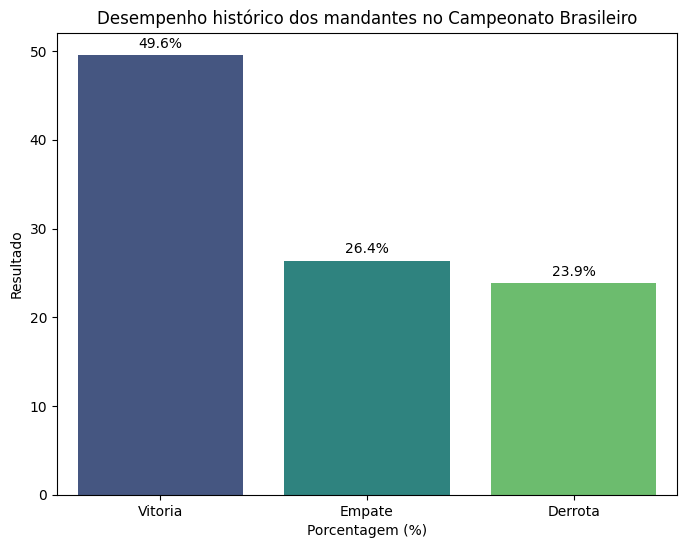

In [ ]:
plt.figure(figsize=(8, 6))

ax = sns.barplot(
      x=resultados_percentuais.index,
      y=resultados_percentuais.values.round(2),
      hue=resultados_percentuais.index,
      palette='viridis',
      legend=False
)

for container in ax.containers:
  ax.bar_label(container, fmt='%.1F%%', padding=3)

plt.title('Desempenho histórico dos mandantes no Campeonato Brasileiro')
plt.xlabel('Porcentagem (%)')
plt.ylabel('Resultado')
plt.savefig('03_desempenho_historico_mandantes.png', dpi=150, bbox_inches='tight')
plt.show()

Gráfico 2: Evolução da taxa de vitórias ao longo dos anos

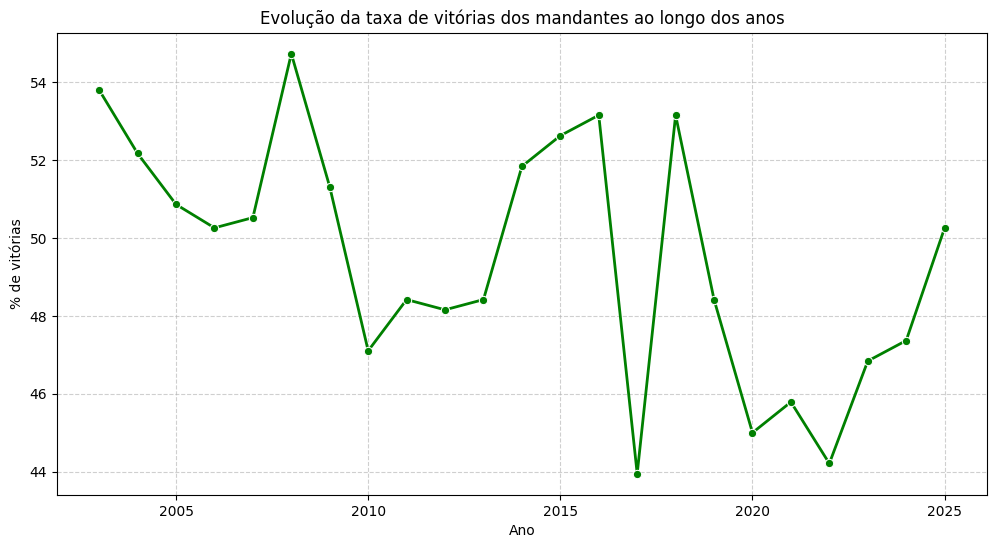

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=evolucao_fator_casa,
    x=evolucao_fator_casa.index,
    y='Vitoria',
    marker='o',
    linewidth=2,
    color='green',
)

plt.title('Evolução da taxa de vitórias dos mandantes ao longo dos anos')
plt.ylabel('% de vitórias')
plt.xlabel('Ano')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('03_evolucao_taxa_de_vitorias_mandantes.png', dpi=150, bbox_inches='tight')
plt.show()

Gráfico 3: Correlação entre Média de Público e Pontuação

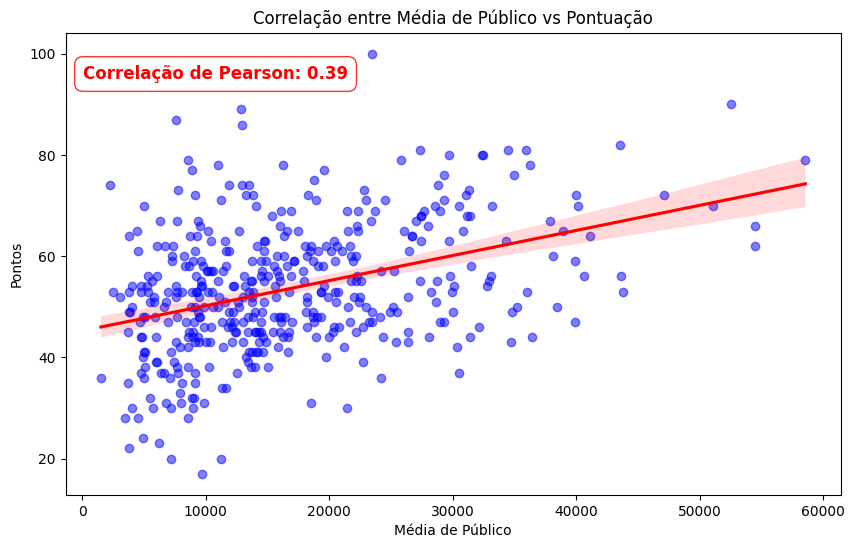

In [ ]:
valor_correlacao = df_desempenho_publico['avg_attendance'].corr(df_desempenho_publico['points'])

plt.figure(figsize=(10, 6))

ax = sns.regplot(
    data=df_desempenho_publico,
    x='avg_attendance',
    y='points',
    scatter_kws={'alpha': 0.5, 'color': 'blue'},
    line_kws={'color': 'red'}
)

x_pos = df_desempenho_publico['avg_attendance'].min() * 0.05
y_pos = df_desempenho_publico['points'].max() * 0.95

texto_correlacao = f'Correlação de Pearson: {valor_correlacao:.2f}'
plt.text(x_pos, y_pos, texto_correlacao, fontsize=12, color='red', fontweight='bold',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='red', boxstyle='round,pad=0.5'))

plt.title('Correlação entre Média de Público vs Pontuação')
plt.xlabel('Média de Público')
plt.ylabel('Pontos')
plt.savefig('03_correlacao_publico_pontos.png', dpi=150, bbox_inches='tight')
plt.show()

Gráfico 4: Times no G4 sempre têm os maiores públicos?

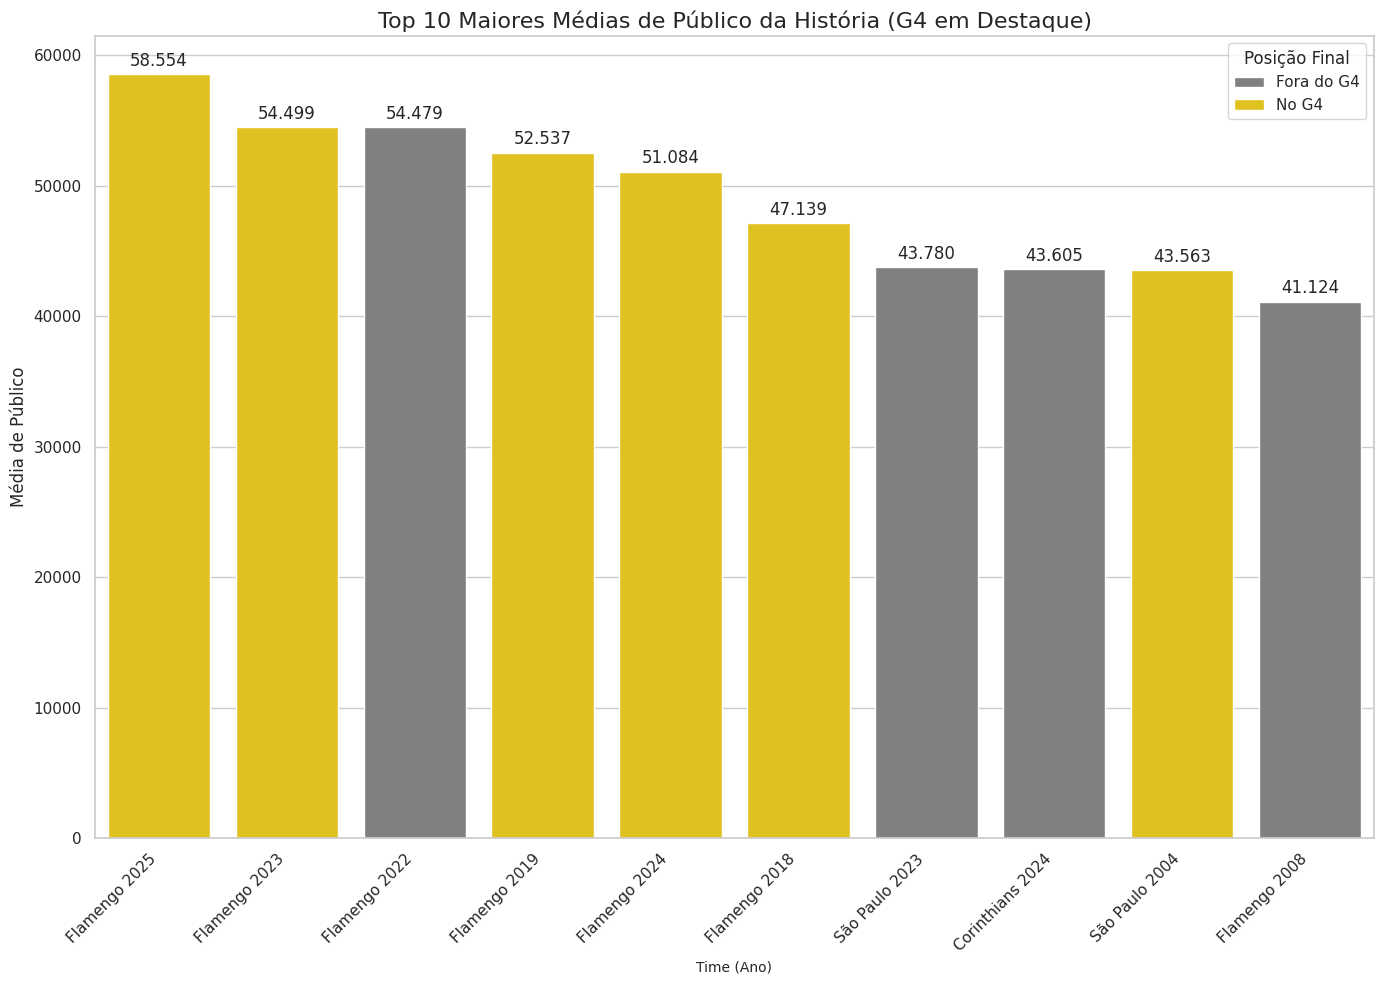

In [ ]:
df_top_10['team'] = df_top_10['team'] + ' ' + df_top_10['season'].astype(str)
df_top_10['No_G4'] = df_top_10['place'] <= 4

plt.figure(figsize=(14, 10))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
     data=df_top_10,
     x='team',
     y='avg_attendance',
     hue='No_G4',
     dodge=False,
     palette={True: 'gold', False: 'gray'}
)

for container in ax.containers:
    valores = container.datavalues
    labels_brasileiros = [f"{valor:,.0f}".replace(',', '.') for valor in valores]
    ax.bar_label(container, labels=labels_brasileiros, padding=3)

plt.title('Top 10 Maiores Médias de Público da História (G4 em Destaque)', fontsize=16)
plt.ylabel('Média de Público', fontsize=12)
plt.xlabel('Time (Ano)', fontsize=10)
plt.xticks(rotation=45, ha='right')


handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Fora do G4', 'No G4'], title='Posição Final')

plt.tight_layout()
plt.savefig('03_tops_maiores_media_publico.png', dpi=150, bbox_inches='tight')
plt.show()